# Gradient Flow Across Layers of a Neural Network (MNIST)

This notebook trains a fully connected network on MNIST and records, **after every epoch**, the size of the gradient of the cost function with respect to the parameters of **each layer**. All the curves are drawn in **one plot**, so you can see at a glance how gradients evolve (and whether they vanish or explode in some layers).

**Everything configurable lives in the next cell:**

| Parameter | Meaning |
|---|---|
| `HIDDEN_UNITS` | list with the number of units of each hidden layer (its length = number of hidden layers) |
| `ACTIVATIONS` | list with one activation per layer (hidden layers **and** the output layer) |
| `COST_FUNCTION` | `'cross_entropy'`, `'mse'`, `'mae'` or `'nll'` |
| `GRAD_NORM` | vector norm used to turn each layer's gradient vector into a scalar: `1`, `2`, `float('inf')`, or any `p > 0` |
| `NORMALIZE_BY_SIZE` | divide each layer's norm by $n^{1/p}$ ($n$ = parameters in the layer) so wide layers aren't inflated |

**How the "gradient of a layer" is defined.** For layer *k* we flatten the gradient w.r.t. its weights and biases and concatenate them into a single vector $g_k = \nabla_{(W_k, b_k)} J$. We then plot $\lVert g_k \rVert_p$. The gradient is evaluated on the (sub)set of training data at the **end of every epoch** (and once before training, as epoch 0), as the *full-batch* gradient — i.e. the average over all those samples — so the curves are not polluted by mini-batch noise.

In [1]:
# !pip install torch torchvision matplotlib numpy   # uncomment if needed
import math
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

## 1. Parameters

In [2]:
# ----------------------------- Architecture -----------------------------
#HIDDEN_UNITS = [128, 64, 32]            # units per hidden layer -> 3 hidden layers here
HIDDEN_UNITS = [32, 32, 32, 32]

# One activation per layer: len(HIDDEN_UNITS) hidden layers + 1 output layer.
# Options: 'relu', 'leaky_relu', 'elu', 'gelu', 'tanh', 'sigmoid', 'softmax', 'identity'
#ACTIVATIONS = ['sigmoid', 'sigmoid', 'sigmoid', 'identity']   # last entry = output layer

#ACTIVATIONS = ['sigmoid', 'sigmoid', 'sigmoid', 'sigmoid', 'identity']
ACTIVATIONS = ['relu', 'relu', 'relu', 'relu', 'identity']

# ----------------------------- Cost function ----------------------------
# 'cross_entropy' : expects raw logits  -> output activation must be 'identity'
# 'nll'           : negative log-likelihood of probabilities -> output activation must be 'softmax'
# 'mse'           : mean squared error vs. one-hot labels (applied to the output activation)
# 'mae'           : mean absolute error vs. one-hot labels (applied to the output activation)
#COST_FUNCTION = 'cross_entropy'
COST_FUNCTION = 'cross_entropy'

# ----------------------------- Gradient norm ----------------------------
# Any p > 0 is accepted: 1 (L1), 2 (Euclidean), float('inf') (max-norm), 0.5, 3, ...
GRAD_NORM = 1

# If True, each layer's norm is divided by n**(1/p), where n = number of parameters of the layer
# (weights + biases) and p = GRAD_NORM. This removes the bias toward bigger layers: for p=2 it is the
# root-mean-square gradient per parameter, for p=1 the mean absolute gradient per parameter.
# (For p = inf nothing changes: the max-norm is already independent of layer size.)
NORMALIZE_BY_SIZE = True

# ----------------------------- Training ---------------------------------
EPOCHS = 60
BATCH_SIZE = 128
LEARNING_RATE = 0.05
OPTIMIZER = 'sgd'                       # 'sgd', 'momentum', 'adam' or 'none' (no weight updates)
SEED = 42

# ----------------------------- Plot options -----------------------------
GRAD_EVAL_SAMPLES = 10_000              # samples used for the end-of-epoch gradient (None = all 60000)
LOG_SCALE = True                        # log y-axis (gradient sizes often span orders of magnitude)

## 2. Helpers: activations, cost functions, norms

In [3]:
ACTIVATION_FUNCTIONS = {
    'relu':       F.relu,
    'leaky_relu': lambda x: F.leaky_relu(x, 0.01),
    'elu':        F.elu,
    'gelu':       F.gelu,
    'tanh':       torch.tanh,
    'sigmoid':    torch.sigmoid,
    'softmax':    lambda x: F.softmax(x, dim=1),
    'identity':   lambda x: x,
}

NUM_CLASSES = 10


def cost_cross_entropy(out, y):          # `out` = logits
    return F.cross_entropy(out, y)

def cost_nll(out, y):                    # `out` = probabilities (softmax)
    return F.nll_loss(torch.log(out.clamp_min(1e-12)), y)

def cost_mse(out, y):                    # `out` = output activation
    return F.mse_loss(out, F.one_hot(y, NUM_CLASSES).float())

def cost_mae(out, y):
    return F.l1_loss(out, F.one_hot(y, NUM_CLASSES).float())

COST_FUNCTIONS = {
    'cross_entropy': cost_cross_entropy,
    'nll':           cost_nll,
    'mse':           cost_mse,
    'mae':           cost_mae,
}


def validate_parameters():
    if len(ACTIVATIONS) != len(HIDDEN_UNITS) + 1:
        raise ValueError(
            f"ACTIVATIONS needs {len(HIDDEN_UNITS) + 1} entries "
            f"({len(HIDDEN_UNITS)} hidden layers + output layer), got {len(ACTIVATIONS)}.")
    for a in ACTIVATIONS:
        if a not in ACTIVATION_FUNCTIONS:
            raise ValueError(f"Unknown activation '{a}'. Options: {list(ACTIVATION_FUNCTIONS)}")
    if COST_FUNCTION not in COST_FUNCTIONS:
        raise ValueError(f"Unknown cost '{COST_FUNCTION}'. Options: {list(COST_FUNCTIONS)}")
    if COST_FUNCTION == 'cross_entropy' and ACTIVATIONS[-1] != 'identity':
        raise ValueError("'cross_entropy' applies softmax internally: set the output activation to 'identity'.")
    if COST_FUNCTION == 'nll' and ACTIVATIONS[-1] != 'softmax':
        raise ValueError("'nll' expects probabilities: set the output activation to 'softmax'.")
    if not (GRAD_NORM == float('inf') or GRAD_NORM > 0):
        raise ValueError("GRAD_NORM must be > 0 (use float('inf') for the max-norm).")


def norm_label(p):
    return {1: 'L1', 2: 'L2'}.get(p, 'L∞' if p == float('inf') else f'L{p}')


def vector_norm(v, p):
    """p-norm of a 1-D tensor, p in (0, inf]. (torch's built-in also handles p<1, but we keep it explicit.)"""
    if p == float('inf'):
        return v.abs().max().item()
    return v.abs().pow(p).sum().pow(1.0 / p).item()


def size_factor(n_params, p):
    # Divisor that makes a p-norm independent of the number of parameters.
    if not NORMALIZE_BY_SIZE or p == float('inf'):
        return 1.0
    return n_params ** (1.0 / p)


validate_parameters()

## 3. Data: MNIST

In [4]:
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

train_set = datasets.MNIST(root='./data', train=True,  download=True)
test_set  = datasets.MNIST(root='./data', train=False, download=True)

MEAN, STD = 0.1307, 0.3081   # standard MNIST statistics

def prep(ds):
    x = ds.data.float().div(255.0).sub(MEAN).div(STD).view(len(ds), -1)   # flatten 28x28 -> 784
    return x.to(device), ds.targets.to(device)

X_train, y_train = prep(train_set)
X_test,  y_test  = prep(test_set)
print('Train:', tuple(X_train.shape), ' Test:', tuple(X_test.shape))

# Fixed subset used to measure the end-of-epoch gradient
n_eval = len(X_train) if GRAD_EVAL_SAMPLES is None else min(GRAD_EVAL_SAMPLES, len(X_train))
eval_idx = torch.randperm(len(X_train), generator=torch.Generator().manual_seed(SEED))[:n_eval].to(device)
X_eval, y_eval = X_train[eval_idx], y_train[eval_idx]

Device: cpu
Train: (60000, 784)  Test: (10000, 784)


## 4. Model

In [5]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_units, activations, output_dim):
        super().__init__()
        sizes = [input_dim] + list(hidden_units) + [output_dim]
        self.layers = nn.ModuleList(nn.Linear(sizes[i], sizes[i + 1]) for i in range(len(sizes) - 1))
        self.acts = [ACTIVATION_FUNCTIONS[a] for a in activations]

    def forward(self, x):
        for layer, act in zip(self.layers, self.acts):
            x = act(layer(x))
        return x


model = MLP(784, HIDDEN_UNITS, ACTIVATIONS, NUM_CLASSES).to(device)
cost_fn = COST_FUNCTIONS[COST_FUNCTION]

layer_names = []
for i, layer in enumerate(model.layers):
    kind = 'Output' if i == len(model.layers) - 1 else f'Hidden {i + 1}'
    layer_names.append(f"{kind}: {layer.in_features}→{layer.out_features} ({ACTIVATIONS[i]})")

print(model)
print('Parameters:', sum(p.numel() for p in model.parameters()))

if OPTIMIZER == 'sgd':
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
elif OPTIMIZER == 'momentum':
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)
elif OPTIMIZER == 'adam':
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
elif OPTIMIZER == 'none':
    optimizer = None                    # weights are never updated
else:
    raise ValueError("OPTIMIZER must be 'sgd', 'momentum', 'adam' or 'none'")

MLP(
  (layers): ModuleList(
    (0): Linear(in_features=784, out_features=32, bias=True)
    (1-3): 3 x Linear(in_features=32, out_features=32, bias=True)
    (4): Linear(in_features=32, out_features=10, bias=True)
  )
)
Parameters: 28618


## 5. Measuring the per-layer gradient

`layer_gradient_norms` computes the **full-batch gradient** of the cost on the evaluation subset (accumulated in chunks to save memory, each chunk weighted by its size so the result equals the average gradient), concatenates each layer's weight and bias gradients into one vector, and returns its `GRAD_NORM`-norm. If `NORMALIZE_BY_SIZE = True`, that norm is divided by $n^{1/p}$ ($n$ = number of parameters in the layer), so layers with many units are not artificially favoured.

In [6]:
def layer_gradient_norms(chunk=2000):
    model.eval()
    model.zero_grad(set_to_none=True)
    total = len(X_eval)
    total_loss = 0.0
    for s in range(0, total, chunk):
        xb, yb = X_eval[s:s + chunk], y_eval[s:s + chunk]
        loss = cost_fn(model(xb), yb) * (len(xb) / total)   # weighted -> sum of chunks = full average
        loss.backward()                                     # grads accumulate in .grad
        total_loss += loss.item()

    norms = []
    for layer in model.layers:
        g = torch.cat([layer.weight.grad.flatten(), layer.bias.grad.flatten()])
        norms.append(vector_norm(g, GRAD_NORM) / size_factor(g.numel(), GRAD_NORM))
    model.zero_grad(set_to_none=True)
    return norms, total_loss


@torch.no_grad()
def evaluate(X, y):
    model.eval()
    out = model(X)
    return cost_fn(out, y).item(), (out.argmax(1) == y).float().mean().item()

## 6. Training loop

In [7]:
grad_history = []                 # grad_history[e][k] = norm of layer k's gradient after epoch e (e=0: before training)
history = {'train_cost': [], 'test_cost': [], 'test_acc': []}

norms, _ = layer_gradient_norms()
grad_history.append(norms)

n_train = len(X_train)
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    if optimizer is not None:                         # with OPTIMIZER = 'none' the weights stay fixed
        model.train()
        perm = torch.randperm(n_train, device=device)
        for s in range(0, n_train, BATCH_SIZE):
            idx = perm[s:s + BATCH_SIZE]
            optimizer.zero_grad(set_to_none=True)
            loss = cost_fn(model(X_train[idx]), y_train[idx])
            loss.backward()
            optimizer.step()

    norms, train_cost = layer_gradient_norms()        # gradient at the END of this epoch
    grad_history.append(norms)
    test_cost, test_acc = evaluate(X_test, y_test)
    history['train_cost'].append(train_cost)
    history['test_cost'].append(test_cost)
    history['test_acc'].append(test_acc)
    print(f"Epoch {epoch:3d}/{EPOCHS} | train cost {train_cost:.4f} | test cost {test_cost:.4f} "
          f"| test acc {test_acc:.4f} | {norm_label(GRAD_NORM)} grad norms: "
          + ", ".join(f"{n:.2e}" for n in norms))
print(f"Done in {time.time() - t0:.1f}s")

Epoch   1/60 | train cost 0.3844 | test cost 0.3764 | test acc 0.8846 | L1 grad norms: 3.14e-03, 8.96e-03, 9.40e-03, 8.83e-03, 1.45e-02


Epoch   2/60 | train cost 0.2513 | test cost 0.2596 | test acc 0.9192 | L1 grad norms: 4.44e-03, 1.21e-02, 1.19e-02, 1.23e-02, 1.96e-02


Epoch   3/60 | train cost 0.1597 | test cost 0.1832 | test acc 0.9449 | L1 grad norms: 1.44e-03, 4.23e-03, 4.37e-03, 4.24e-03, 7.11e-03


Epoch   4/60 | train cost 0.1286 | test cost 0.1521 | test acc 0.9534 | L1 grad norms: 1.18e-03, 3.09e-03, 3.06e-03, 2.90e-03, 5.18e-03


Epoch   5/60 | train cost 0.1193 | test cost 0.1499 | test acc 0.9542 | L1 grad norms: 2.01e-03, 5.77e-03, 5.24e-03, 4.80e-03, 8.31e-03


...

Epoch  56/60 | train cost 0.0074 | test cost 0.1794 | test acc 0.9684 | L1 grad norms: 5.03e-04, 1.36e-03, 1.01e-03, 7.85e-04, 1.03e-03


Epoch  57/60 | train cost 0.0038 | test cost 0.1759 | test acc 0.9684 | L1 grad norms: 2.85e-04, 7.96e-04, 5.73e-04, 4.55e-04, 6.26e-04


Epoch  58/60 | train cost 0.0094 | test cost 0.1974 | test acc 0.9664 | L1 grad norms: 1.05e-03, 3.41e-03, 3.06e-03, 2.49e-03, 3.60e-03


Epoch  59/60 | train cost 0.0023 | test cost 0.1856 | test acc 0.9708 | L1 grad norms: 2.29e-04, 6.12e-04, 4.76e-04, 3.96e-04, 8.11e-04


Epoch  60/60 | train cost 0.0020 | test cost 0.1885 | test acc 0.9700 | L1 grad norms: 1.81e-04, 4.25e-04, 2.93e-04, 2.31e-04, 3.43e-04
Done in 51.0s


## 7. Gradient of each layer across epochs (single plot)

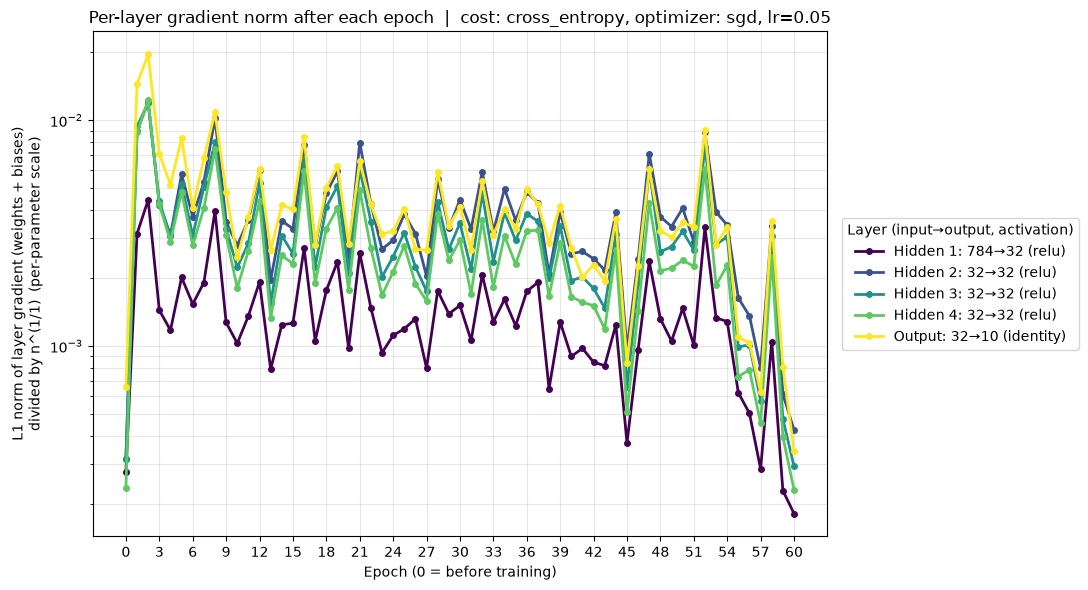

In [8]:
grad_arr = np.array(grad_history)          # shape: (EPOCHS + 1, n_layers)
epochs = np.arange(grad_arr.shape[0])      # 0 = before training

fig, ax = plt.subplots(figsize=(11, 6))
cmap = plt.get_cmap('viridis')
n_layers = grad_arr.shape[1]
for k in range(n_layers):
    ax.plot(epochs, grad_arr[:, k], marker='o', markersize=4, linewidth=2,
            color=cmap(k / max(n_layers - 1, 1)), label=layer_names[k])

ax.set_xlabel('Epoch (0 = before training)')
ylabel = f'{norm_label(GRAD_NORM)} norm of layer gradient (weights + biases)'
if NORMALIZE_BY_SIZE and GRAD_NORM != float('inf'):
    ylabel += f'\ndivided by n^(1/{GRAD_NORM})  (per-parameter scale)'
ax.set_ylabel(ylabel)
ax.set_title(f'Per-layer gradient norm after each epoch  |  cost: {COST_FUNCTION}, '
             f'optimizer: {OPTIMIZER}' + ('' if OPTIMIZER == 'none' else f', lr={LEARNING_RATE}'))
ax.set_xticks(epochs[::max(1, len(epochs) // 20)])
if LOG_SCALE:
    ax.set_yscale('log')
ax.grid(True, which='both', alpha=0.3)
ax.legend(title='Layer (input→output, activation)', loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

### Optional: training context
Cost and accuracy on the same epochs, to relate gradient behaviour to learning progress.

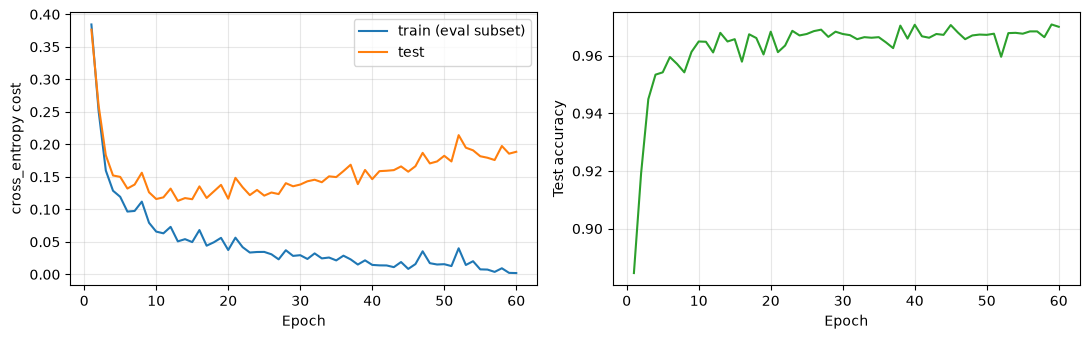

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
ep = np.arange(1, EPOCHS + 1)
a1.plot(ep, history['train_cost'], label='train (eval subset)')
a1.plot(ep, history['test_cost'], label='test')
a1.set_xlabel('Epoch'); a1.set_ylabel(f'{COST_FUNCTION} cost'); a1.legend(); a1.grid(alpha=0.3)
a2.plot(ep, history['test_acc'], color='tab:green')
a2.set_xlabel('Epoch'); a2.set_ylabel('Test accuracy'); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Things to try

* **No optimizer:** `OPTIMIZER = 'none'` freezes the weights, so every epoch reports the gradient at the initial point. The curves are flat, which is a useful baseline for how much of the variation elsewhere comes from training.
* **Vanishing gradients:** many `sigmoid`/`tanh` hidden layers with plain SGD — the earliest layers' curves will sit orders of magnitude below the output layer's.
* **ReLU vs. sigmoid:** set `ACTIVATIONS = ['relu', 'relu', 'relu', 'identity']` and compare the spread between layers.
* **Different norms:** `GRAD_NORM = float('inf')` shows the largest single component; with `NORMALIZE_BY_SIZE = False`, `1` grows with the number of parameters in the layer, so wide layers look larger; set it to `True` to compare layers fairly.
* **Different costs:** `COST_FUNCTION = 'mse'` with `ACTIVATIONS[-1] = 'softmax'` (or `'sigmoid'`) usually gives much smaller gradients than cross-entropy.
* **Deeper networks:** e.g. `HIDDEN_UNITS = [64] * 8` with `ACTIVATIONS = ['tanh'] * 8 + ['identity']`.